# Yapay Zeka Dersi - Grup 5 Projesi
**Random Forest & XGBoost Sınıflandırıcı** | Wisconsin Meme Kanseri Veri Seti

YAPAY ZEKA DERSİ - GRUP 5 PROJESİ  
Konu     : Gözetimli Öğrenme - Karar Ağaçları & Ensemble Yöntemler  
Algoritma: Random Forest & XGBoost Sınıflandırıcı  
Veri seti: Wisconsin Meme Kanseri Teşhis Veri Seti (UCI / scikit-learn)  
           569 hasta, 30 sayısal öznitelik, hedef: habis (kötü huylu) mu?

## 1) KÜTÜPHANELER VE AYARLAR

In [20]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

KLASOR = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
GRAFIK = os.path.join(KLASOR, "grafikler")
VERI = os.path.join(KLASOR, "veri")
os.makedirs(GRAFIK, exist_ok=True)
os.makedirs(VERI, exist_ok=True)
RASTGELE = 42


def kaydet(ad):
    """Grafiği grafikler/ klasörüne kaydeder ve gösterir."""
    plt.tight_layout()
    plt.savefig(os.path.join(GRAFIK, ad), bbox_inches="tight")
    plt.show()

## 2) VERİ SETİNİ ÇEKME (YÜKLEME)

In [21]:
# Veri seti scikit-learn ile birlikte gelir; internet gerekmez.
# Orijinal kodlamada 0 = habis, 1 = iyi huylu. Habis sınıfı "pozitif" (1) olsun diye ters çeviriyoruz:
ham = load_breast_cancer(as_frame=True)
df = ham.frame.copy()
df["hedef"] = 1 - df["target"]          # 1 = Habis (kötü huylu), 0 = İyi huylu
df = df.drop(columns="target")
df.to_csv(os.path.join(VERI, "meme_kanseri.csv"), index=False)   # CSV olarak da saklıyoruz

print("Veri boyutu:", df.shape)
print("Öznitelik sayısı:", df.shape[1] - 1)
print("Eksik değer sayısı:", int(df.isna().sum().sum()))
df.head()

Veri boyutu: (569, 31)
Öznitelik sayısı: 30
Eksik değer sayısı: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,hedef
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 3) KEŞİFSEL VERİ ANALİZİ (EDA)

hedef
İyi huylu    357
Habis        212
Name: count, dtype: int64

                        count    mean     std     min     25%     50%     75%  \
mean radius             569.0   14.13    3.52    6.98   11.70   13.37   15.78   
mean texture            569.0   19.29    4.30    9.71   16.17   18.84   21.80   
mean perimeter          569.0   91.97   24.30   43.79   75.17   86.24  104.10   
mean area               569.0  654.89  351.91  143.50  420.30  551.10  782.70   
mean smoothness         569.0    0.10    0.01    0.05    0.09    0.10    0.11   
mean compactness        569.0    0.10    0.05    0.02    0.06    0.09    0.13   
mean concavity          569.0    0.09    0.08    0.00    0.03    0.06    0.13   
mean concave points     569.0    0.05    0.04    0.00    0.02    0.03    0.07   
mean symmetry           569.0    0.18    0.03    0.11    0.16    0.18    0.20   
mean fractal dimension  569.0    0.06    0.01    0.05    0.06    0.06    0.07   

                            max  
mean ra

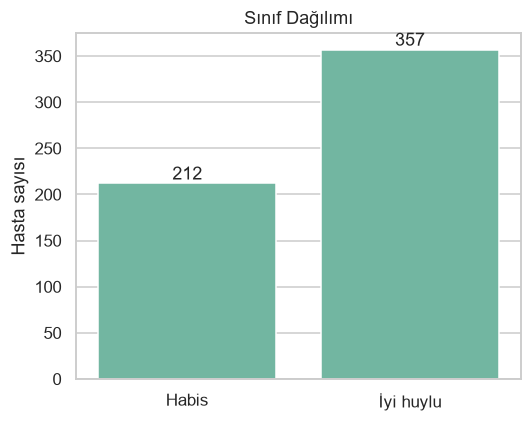

In [22]:
print(df["hedef"].value_counts().rename({0: "İyi huylu", 1: "Habis"}))
print()
print(df.describe().T.head(10).round(2))

# 3.1 Sınıf dağılımı
plt.figure(figsize=(5, 4))
ax = sns.countplot(x=df["hedef"].map({0: "İyi huylu", 1: "Habis"}))
ax.set_title("Sınıf Dağılımı")
ax.set_xlabel("")
ax.set_ylabel("Hasta sayısı")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
kaydet("01_sinif_dagilimi.png")

## 3.2 Korelasyon ısı haritası (hedefle en ilişkili 10 öznitelik)

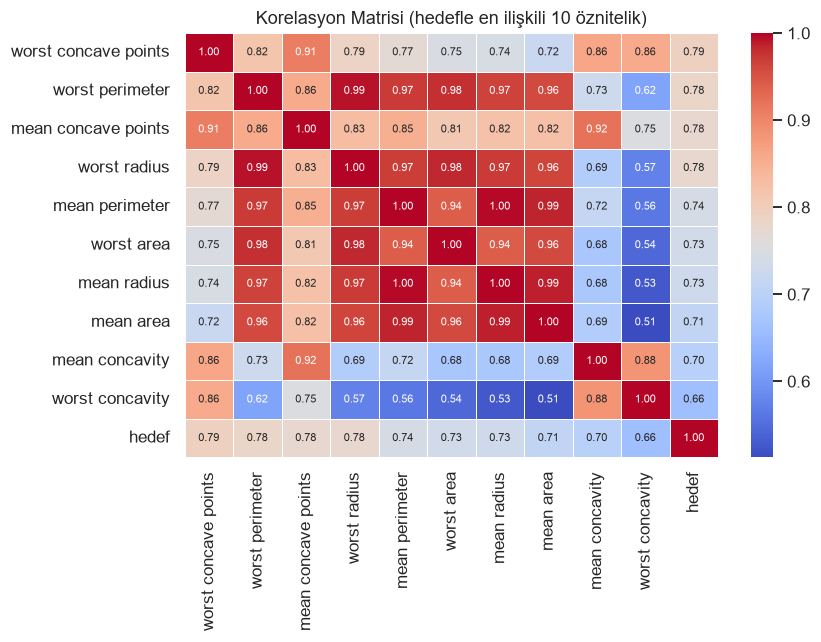

In [23]:
en_iliskili = df.corr()["hedef"].abs().sort_values(ascending=False).index[1:11]
plt.figure(figsize=(8, 6))
sns.heatmap(df[list(en_iliskili) + ["hedef"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", linewidths=0.5, annot_kws={"size": 7})
plt.title("Korelasyon Matrisi (hedefle en ilişkili 10 öznitelik)")
kaydet("02_korelasyon.png")

## 3.3 Seçili özniteliklerin sınıfa göre dağılımı

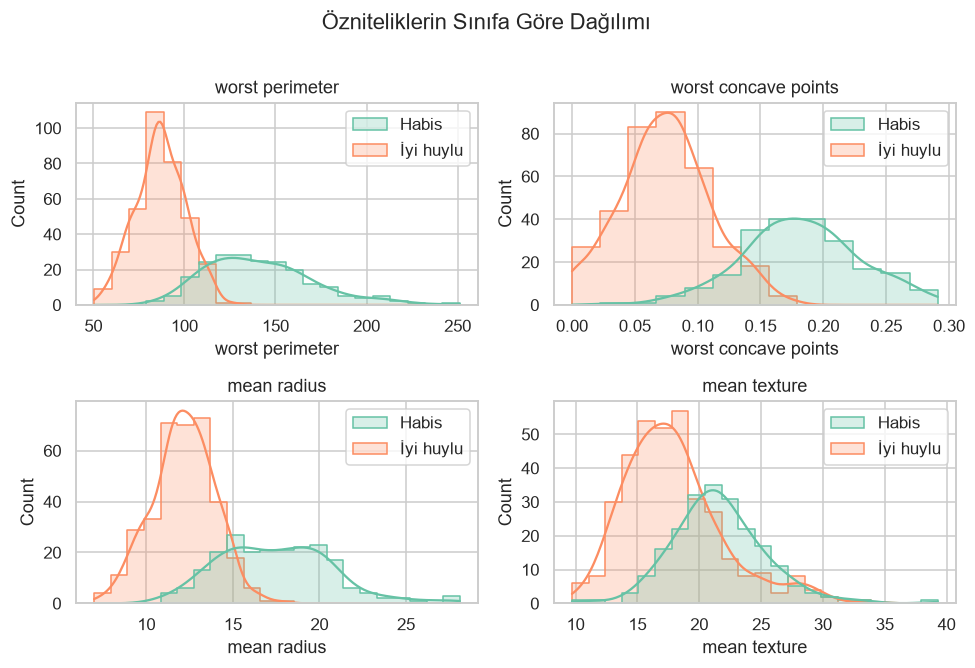

In [24]:
secili = ["worst perimeter", "worst concave points", "mean radius", "mean texture"]
fig, eksenler = plt.subplots(2, 2, figsize=(9, 6))
for ax, sutun in zip(eksenler.ravel(), secili):
    sns.histplot(data=df, x=sutun, hue=df["hedef"].map({0: "İyi huylu", 1: "Habis"}),
                 kde=True, ax=ax, element="step")
    ax.set_title(sutun)
    ax.legend_.set_title("")
fig.suptitle("Özniteliklerin Sınıfa Göre Dağılımı", y=1.01)
kaydet("03_oznitelik_dagilimlari.png")

## 4) EĞİTİM / TEST AYIRMA

In [25]:
X = df.drop(columns="hedef")
y = df["hedef"]
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RASTGELE)
print("Eğitim:", X_egitim.shape, "| Test:", X_test.shape)
# Not: Ağaç tabanlı modeller ölçeklemeye (StandardScaler) ihtiyaç duymaz.

Eğitim: (455, 30) | Test: (114, 30)


## 5) MODELLERİN EĞİTİMİ

In [26]:
modeller = {
    "Karar Ağacı": DecisionTreeClassifier(random_state=RASTGELE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RASTGELE, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                             subsample=0.8, colsample_bytree=0.8,
                             eval_metric="logloss", random_state=RASTGELE),
}

tahminler, olasiliklar = {}, {}
for ad, model in modeller.items():
    model.fit(X_egitim, y_egitim)
    tahminler[ad] = model.predict(X_test)
    olasiliklar[ad] = model.predict_proba(X_test)[:, 1]
    print(f"{ad:15s} eğitildi.")

Karar Ağacı     eğitildi.
Random Forest   eğitildi.
XGBoost         eğitildi.


## 6) BAŞARI METRİKLERİ

               Accuracy  Precision  Recall      F1  ROC-AUC
Model                                                      
Karar Ağacı      0.9298     0.9048  0.9048  0.9048   0.9246
Random Forest    0.9649     1.0000  0.9048  0.9500   0.9942
XGBoost          0.9737     1.0000  0.9286  0.9630   0.9921


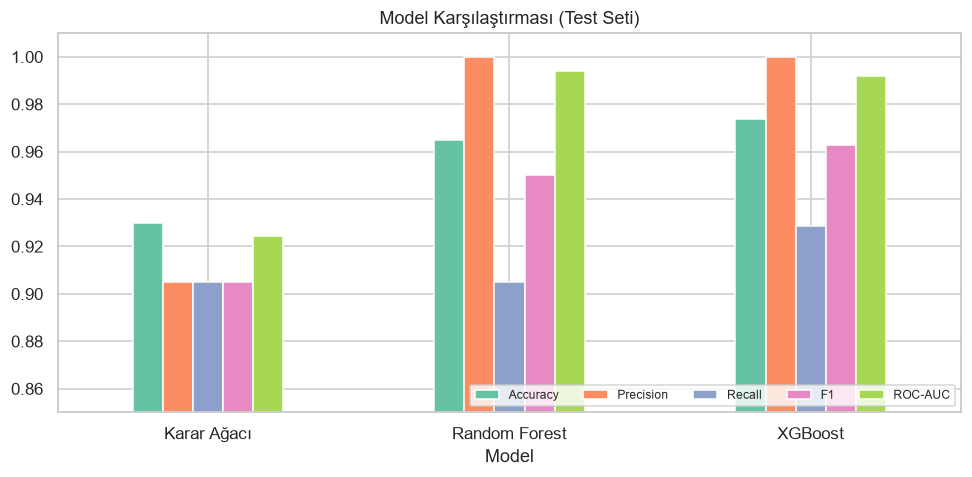

In [27]:
satirlar = []
for ad in modeller:
    satirlar.append({
        "Model": ad,
        "Accuracy": accuracy_score(y_test, tahminler[ad]),
        "Precision": precision_score(y_test, tahminler[ad]),
        "Recall": recall_score(y_test, tahminler[ad]),
        "F1": f1_score(y_test, tahminler[ad]),
        "ROC-AUC": roc_auc_score(y_test, olasiliklar[ad]),
    })
sonuc = pd.DataFrame(satirlar).set_index("Model").round(4)
sonuc.to_csv(os.path.join(VERI, "model_sonuclari.csv"))
print(sonuc)

sonuc.plot(kind="bar", figsize=(9, 4.5), ylim=(0.85, 1.01))
plt.title("Model Karşılaştırması (Test Seti)")
plt.xticks(rotation=0)
plt.legend(loc="lower right", ncol=5, fontsize=8)
kaydet("04_model_karsilastirma.png")

## 7) KARMAŞIKLIK MATRİSİ (CONFUSION MATRIX)

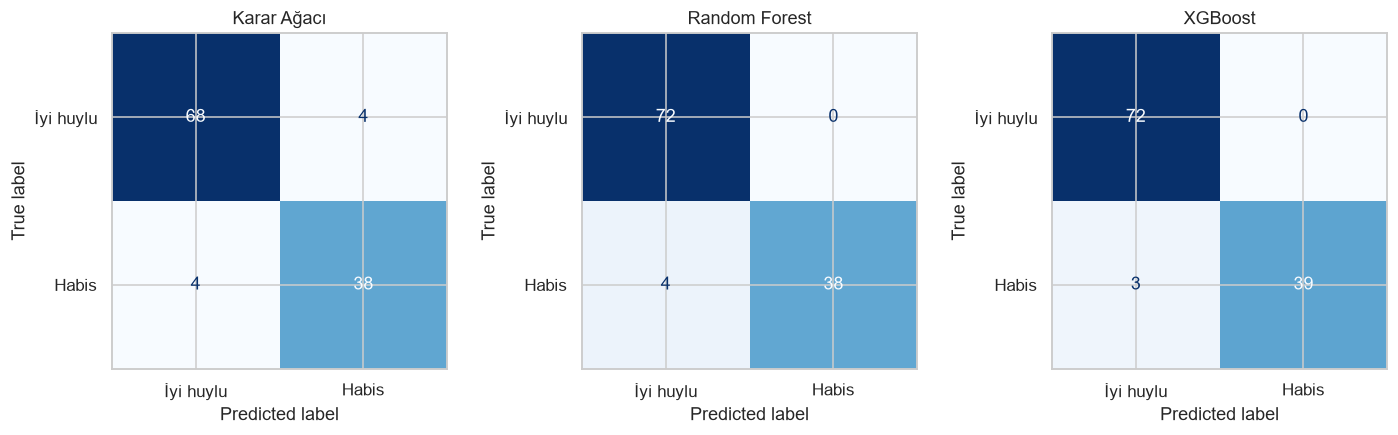

Random Forest - Sınıflandırma Raporu
              precision    recall  f1-score   support

   İyi huylu       0.95      1.00      0.97        72
       Habis       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114

XGBoost - Sınıflandırma Raporu
              precision    recall  f1-score   support

   İyi huylu       0.96      1.00      0.98        72
       Habis       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



In [28]:
fig, eksenler = plt.subplots(1, 3, figsize=(13, 4))
for ax, ad in zip(eksenler, modeller):
    ConfusionMatrixDisplay(confusion_matrix(y_test, tahminler[ad]),
                           display_labels=["İyi huylu", "Habis"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(ad)
kaydet("05_karmasiklik_matrisleri.png")

print("Random Forest - Sınıflandırma Raporu")
print(classification_report(y_test, tahminler["Random Forest"], target_names=["İyi huylu", "Habis"]))
print("XGBoost - Sınıflandırma Raporu")
print(classification_report(y_test, tahminler["XGBoost"], target_names=["İyi huylu", "Habis"]))

## 8) ROC EĞRİSİ

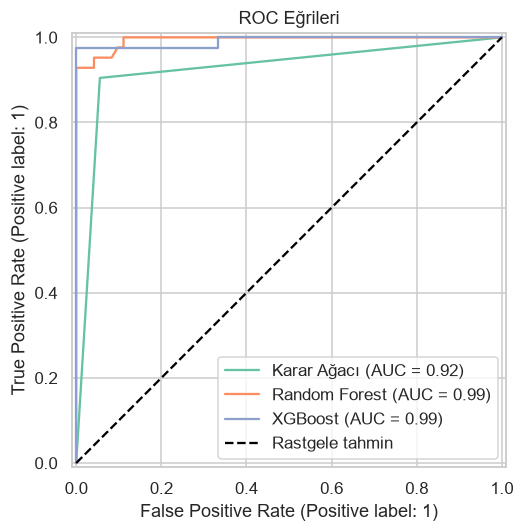

In [29]:
fig, ax = plt.subplots(figsize=(6, 5))
for ad, model in modeller.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name=ad)
ax.plot([0, 1], [0, 1], "k--", label="Rastgele tahmin")
ax.set_title("ROC Eğrileri")
ax.legend(loc="lower right")
kaydet("06_roc_egrisi.png")

## 9) ÇAPRAZ DOĞRULAMA (5 KATLI)

Karar Ağacı     ortalama: 0.9104  (± 0.0279)
Random Forest   ortalama: 0.9543  (± 0.0102)
XGBoost         ortalama: 0.9666  (± 0.0187)


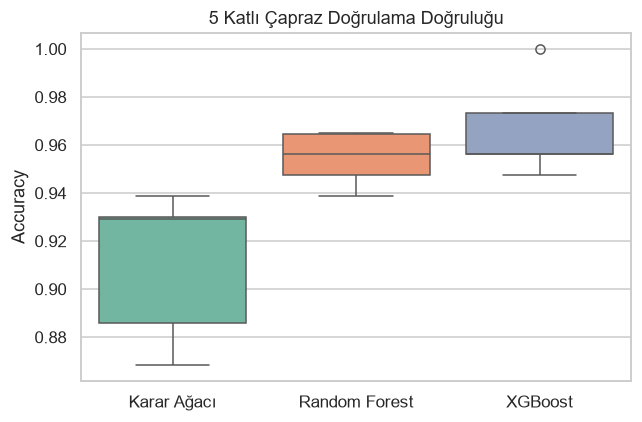

In [30]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RASTGELE)
cv_sonuc = {}
for ad, model in modeller.items():
    skor = cross_val_score(model, X, y, cv=kfold, scoring="accuracy")
    cv_sonuc[ad] = skor
    print(f"{ad:15s} ortalama: {skor.mean():.4f}  (± {skor.std():.4f})")

plt.figure(figsize=(6, 4))
sns.boxplot(data=pd.DataFrame(cv_sonuc))
plt.title("5 Katlı Çapraz Doğrulama Doğruluğu")
plt.ylabel("Accuracy")
kaydet("07_capraz_dogrulama.png")

## 10) ÖZNİTELİK ÖNEMLERİ

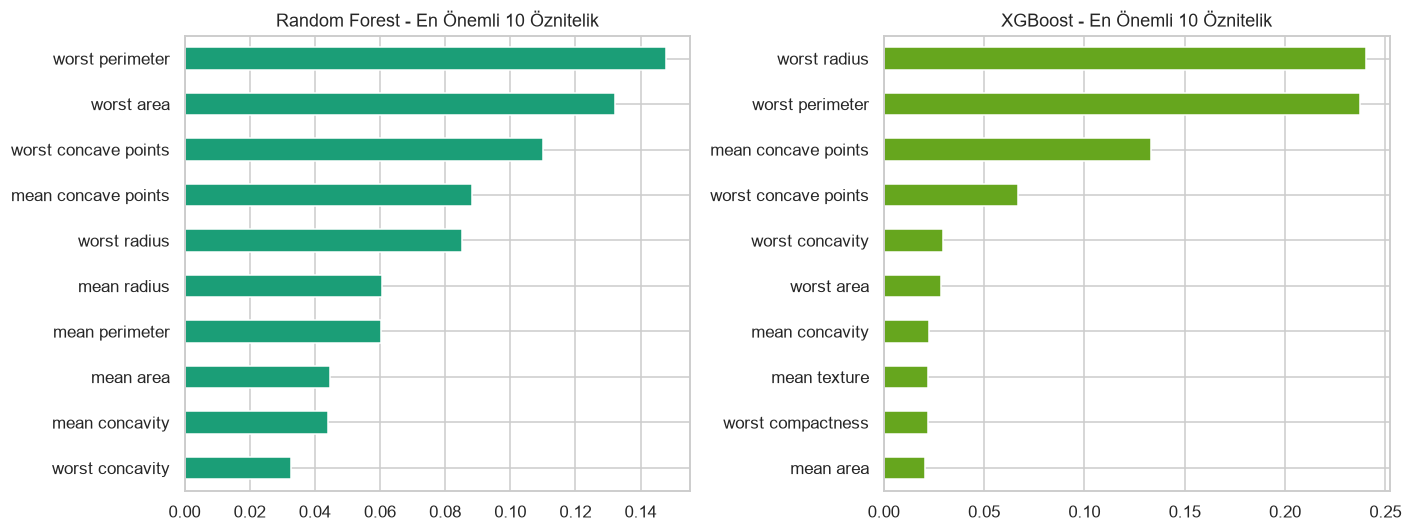

In [31]:
onem = pd.DataFrame({
    "Random Forest": modeller["Random Forest"].feature_importances_,
    "XGBoost": modeller["XGBoost"].feature_importances_,
}, index=X.columns)

fig, eksenler = plt.subplots(1, 2, figsize=(13, 5))
for ax, ad in zip(eksenler, onem.columns):
    onem[ad].sort_values().tail(10).plot(kind="barh", ax=ax, color="#66a61e" if ad == "XGBoost" else "#1b9e77")
    ax.set_title(f"{ad} - En Önemli 10 Öznitelik")
kaydet("08_oznitelik_onemleri.png")

## 11) HİPERPARAMETRE ETKİSİ: AĞAÇ SAYISI

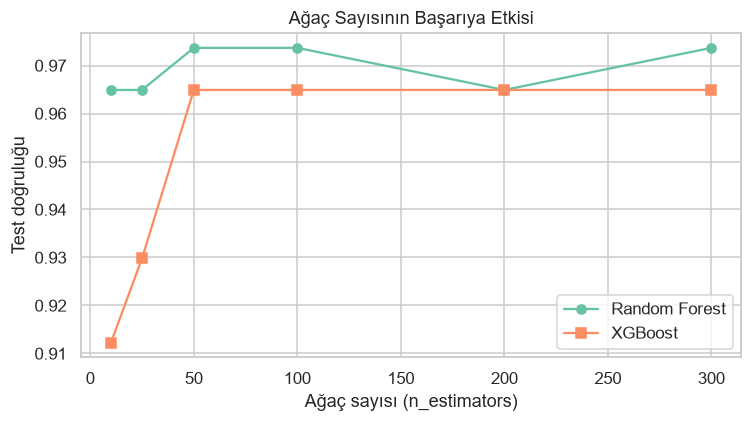

In [32]:
agac_sayilari = [10, 25, 50, 100, 200, 300]
rf_skor, xgb_skor = [], []
for n in agac_sayilari:
    rf = RandomForestClassifier(n_estimators=n, random_state=RASTGELE, n_jobs=-1).fit(X_egitim, y_egitim)
    xg = XGBClassifier(n_estimators=n, learning_rate=0.05, max_depth=4, eval_metric="logloss",
                       random_state=RASTGELE).fit(X_egitim, y_egitim)
    rf_skor.append(accuracy_score(y_test, rf.predict(X_test)))
    xgb_skor.append(accuracy_score(y_test, xg.predict(X_test)))

plt.figure(figsize=(7, 4))
plt.plot(agac_sayilari, rf_skor, "o-", label="Random Forest")
plt.plot(agac_sayilari, xgb_skor, "s-", label="XGBoost")
plt.xlabel("Ağaç sayısı (n_estimators)")
plt.ylabel("Test doğruluğu")
plt.title("Ağaç Sayısının Başarıya Etkisi")
plt.legend()
kaydet("09_agac_sayisi_etkisi.png")

## 12) HİPERPARAMETRE OPTİMİZASYONU (GridSearchCV)

In [33]:
parametre_izgarasi = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, None],
    "min_samples_split": [2, 5],
}
arama = GridSearchCV(RandomForestClassifier(random_state=RASTGELE, n_jobs=-1),
                     parametre_izgarasi, cv=5, scoring="roc_auc", n_jobs=-1)
arama.fit(X_egitim, y_egitim)
print("En iyi parametreler:", arama.best_params_)
print("En iyi CV ROC-AUC  :", round(arama.best_score_, 4))
print("Test doğruluğu     :", round(accuracy_score(y_test, arama.best_estimator_.predict(X_test)), 4))

En iyi parametreler: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
En iyi CV ROC-AUC  : 0.9906
Test doğruluğu     : 0.9737


## 13) TEK KARAR AĞACI GÖRSELİ (teori için)

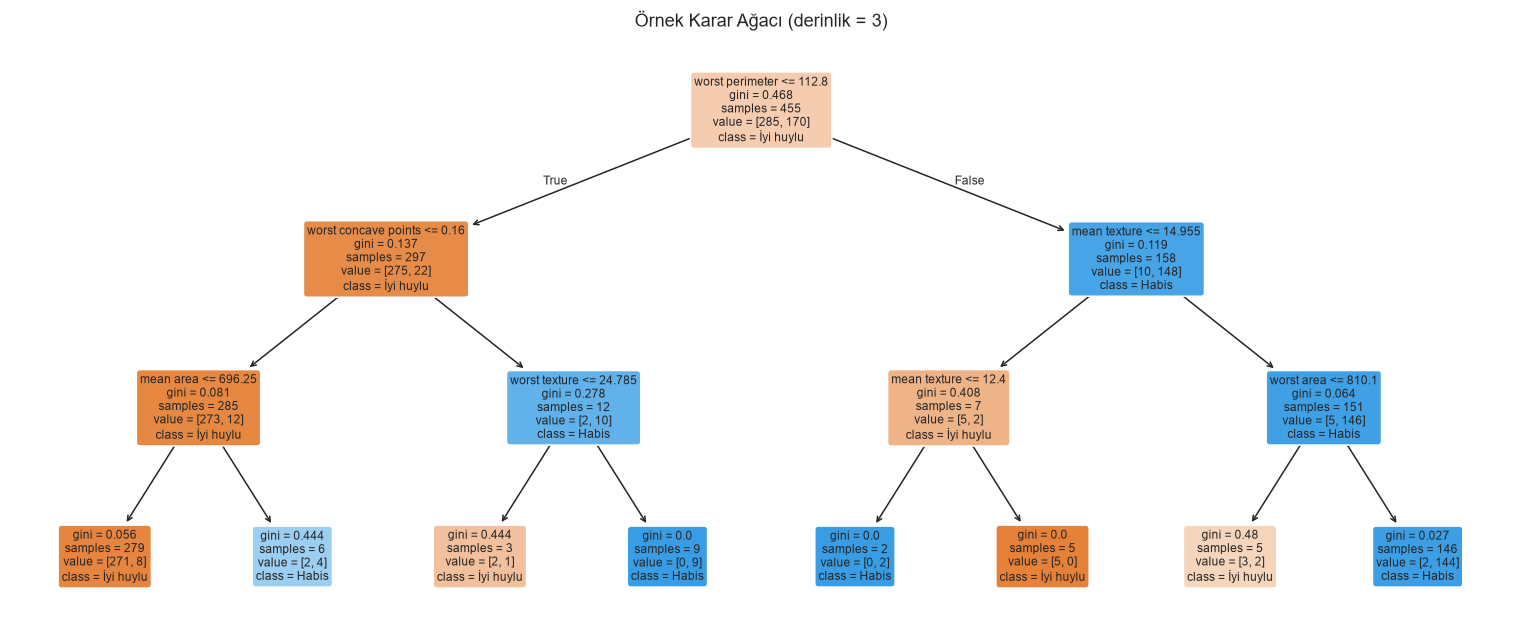

In [34]:
kucuk_agac = DecisionTreeClassifier(max_depth=3, random_state=RASTGELE).fit(X_egitim, y_egitim)
plt.figure(figsize=(14, 6))
plot_tree(kucuk_agac, feature_names=X.columns, class_names=["İyi huylu", "Habis"],
          filled=True, rounded=True, fontsize=8)
plt.title("Örnek Karar Ağacı (derinlik = 3)")
kaydet("10_ornek_karar_agaci.png")

## 14) YENİ / GÖRÜLMEMİŞ VERİ İLE CANLI TAHMİN

In [35]:
# Ortalama bir hastadan başlayıp birkaç ölçümü değiştirerek sınıfta canlı deneme yapılabilir.
def tahmin_et(ornek, etiket="Yeni hasta"):
    ornek = pd.DataFrame([ornek], columns=X.columns)
    print(f"--- {etiket} ---")
    for ad in ["Random Forest", "XGBoost"]:
        p = modeller[ad].predict_proba(ornek)[0, 1]
        karar = "HABİS" if p >= 0.5 else "İYİ HUYLU"
        print(f"{ad:14s}: {karar:9s} (habis olasılığı: %{p * 100:.1f})")
    print()

# a) Test setinden rastgele bir gerçek örnek
i = np.random.RandomState(7).randint(len(X_test))
tahmin_et(X_test.iloc[i], f"Test örneği #{i} (gerçek etiket: {'HABİS' if y_test.iloc[i] else 'İYİ HUYLU'})")

# b) Elle girilen örnek: ortalama değerleri büyütülmüş (habis benzeri) hasta
elle = X.mean().copy()
elle["mean radius"] = 20.0
elle["mean perimeter"] = 130.0
elle["mean area"] = 1200.0
elle["worst radius"] = 25.0
elle["worst perimeter"] = 170.0
elle["worst concave points"] = 0.25
tahmin_et(elle, "Elle girilen örnek (büyük tümör ölçümleri)")

# c) Elle girilen örnek: ortalamadan küçük ölçümler
kucuk = X.mean().copy()
kucuk["mean radius"] = 11.0
kucuk["mean perimeter"] = 72.0
kucuk["mean area"] = 380.0
kucuk["worst radius"] = 12.5
kucuk["worst perimeter"] = 82.0
kucuk["worst concave points"] = 0.05
tahmin_et(kucuk, "Elle girilen örnek (küçük tümör ölçümleri)")

--- Test örneği #47 (gerçek etiket: HABİS) ---
Random Forest : HABİS     (habis olasılığı: %81.0)
XGBoost       : HABİS     (habis olasılığı: %99.8)

--- Elle girilen örnek (büyük tümör ölçümleri) ---
Random Forest : HABİS     (habis olasılığı: %88.0)
XGBoost       : HABİS     (habis olasılığı: %98.5)

--- Elle girilen örnek (küçük tümör ölçümleri) ---
Random Forest : İYİ HUYLU (habis olasılığı: %18.0)
XGBoost       : İYİ HUYLU (habis olasılığı: %7.7)



## 15) SONUÇ

In [36]:
print("ÖZET TABLO (Test Seti)")
print(sonuc)
print("\nEn iyi model (ROC-AUC'ye göre):", sonuc["ROC-AUC"].idxmax())
print("Grafikler kaydedildi ->", GRAFIK)

ÖZET TABLO (Test Seti)
               Accuracy  Precision  Recall      F1  ROC-AUC
Model                                                      
Karar Ağacı      0.9298     0.9048  0.9048  0.9048   0.9246
Random Forest    0.9649     1.0000  0.9048  0.9500   0.9942
XGBoost          0.9737     1.0000  0.9286  0.9630   0.9921

En iyi model (ROC-AUC'ye göre): Random Forest
Grafikler kaydedildi -> C:\Users\efe_e\Desktop\selma_bulut_yapay_zeka_projesi\selma_bulut_yapay_zeka_projesi\grafikler
